# Scikit-learn essentials for practical data analysis

**A practical tutorial with toy data, explanations, exercises, and saved outputs.**

**Goal:** become comfortable turning a pandas table into a fitted model, checking its
predictions, and trying a sensible alternative. We use one small, synthetic hourly
energy dataset generated inside this notebook. **There are no CSV files to download
and no network calls in the code.**

You already know the mathematical idea of regression. Here we concentrate on the
Python objects, the arguments each method expects, and the sequence of operations.

## Reading routes

| Route | Sections | Suggested time |
|---|---|---|
| Core workflow | 0–10, then 13 | About 60–90 minutes, including small experiments |
| Tuning and feature maps | 11–12, before the final assessment in 13 | Another 20–30 minutes |
| Categorical inputs | 14, an independent miniature example | About 10 minutes |
| Reference | 15–17 | Method sheet, common errors, exercise answers |

Work through one code cell at a time. Predict what it will return before running it.
You can also **restart the kernel and run all cells**: every executable cell is complete.
The optional sections can be skipped on a first pass; section 13 works either way.

The sequence is: **data → X and y → split → fit → predict → evaluate → pipeline → compare**.


## 0. Select your environment and import the basics

In VS Code, choose **Python (sklearn_tutorial)** in the notebook's upper-right kernel selector.
The first cell prints the actual Python executable, so you can check that the notebook
uses your intended environment. Activating an environment in a terminal does not by
itself switch a notebook's kernel.

If you have not yet created that environment, these are **terminal commands**, not notebook code:

```bash
conda create -n sklearn_tutorial python=3.12 ipykernel numpy pandas matplotlib scikit-learn
conda activate sklearn_tutorial
python -m ipykernel install --user --name sklearn_tutorial --display-name "Python (sklearn_tutorial)"
```

If it already exists, select its kernel and continue. This notebook does not install
packages or change your environments automatically.

We introduce sklearn imports near the section that first uses them. Each import only
needs to run once per kernel session; you may collect them at the top later.


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

print("Python executable:", sys.executable)
print("Python:", sys.version.split()[0])
print("numpy:", np.__version__, "| pandas:", pd.__version__)
print("matplotlib:", plt.matplotlib.__version__, "| sklearn:", sklearn.__version__)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False})


Python executable: /opt/codex/runtimes/codex-primary-runtime/dependencies/python/bin/python
Python: 3.12.14
numpy: 2.3.5 | pandas: 2.2.3
matplotlib: 3.10.8 | sklearn: 1.8.0


### Which library does which job?

| Library or sklearn module | What we use it for |
|---|---|
| `numpy` | Arrays, random toy data, arithmetic |
| `pandas` | Tables, timestamps, column selection, lags |
| `matplotlib.pyplot` | Figures and axes |
| `sklearn.linear_model` | `LinearRegression` and `Ridge` |
| `sklearn.dummy` | A deliberately simple prediction baseline |
| `sklearn.metrics` | MAE, MSE, and R² |
| `sklearn.impute` / `sklearn.preprocessing` | Fill missing inputs; scale features; encode categories |
| `sklearn.pipeline` | Chain preparation and prediction into one object |
| `sklearn.ensemble` | A random forest comparison |
| `sklearn.model_selection` | Chronological validation and a small parameter search |

For example, `from sklearn.linear_model import Ridge` imports a **class**.
`Ridge(alpha=10)` creates a model **object**. `model.fit(...)` calls a **method** of
that object. You do not separately import `fit` or `predict`.


## 1. Make a small toy forecasting dataset

Each row represents one hour. The target is gas generation during that hour, in MW.
The toy formula combines daily demand, weekdays, weather, and persistent noise.
It is invented for learning and is not a model of a particular electricity market.

**Forecast rule:** immediately before hour `t` begins, predict generation during `t`.
Measurements through `t-1` are available, and the calendar for `t` is known.

Validation and test predictions are **successive one-hour-ahead forecasts**. When a
new hour finishes, its outcome may become a historical input for a later forecast.
The fitted coefficients stay fixed within each evaluation block. This is not a forecast
of an entire future month from one initial date.

**Run the next supplied data-making cell and move on.** Understanding its exact formula
is not required to learn sklearn. Around 2% of each weather sensor's readings are missing;
all target measurements are observed.


In [2]:
rng = np.random.default_rng(2026)
index = pd.date_range("2024-01-01", periods=90 * 24, freq="h", tz="UTC")
hour = np.asarray(index.hour)
day = np.arange(len(index)) / 24.0
is_weekday = np.asarray(index.dayofweek < 5, dtype=float)

temperature_state = np.zeros(len(index))
wind_state = np.zeros(len(index))
generation_state = np.zeros(len(index))
for t in range(1, len(index)):
    temperature_state[t] = 0.96 * temperature_state[t-1] + rng.normal(0, 0.5)
    wind_state[t] = 0.90 * wind_state[t-1] + rng.normal(0, 0.7)
    generation_state[t] = 0.65 * generation_state[t-1] + rng.normal(0, 7)

temperature = (15 + 7 * np.sin(2*np.pi*(hour-8)/24)
               + 2 * np.sin(2*np.pi*day/30) + temperature_state)
wind_speed = np.maximum(0, 6 + wind_state)
generation = (420 + 55*np.sin(2*np.pi*(hour-7)/24) + 25*is_weekday
              + 7*np.maximum(15-temperature, 0)
              + 5*np.maximum(temperature-22, 0)
              - 9*wind_speed + generation_state + rng.normal(0, 7, len(index)))

raw = pd.DataFrame({"generation_mw": generation, "temperature_c": temperature,
                    "wind_speed": wind_speed}, index=index)
raw.index.name = "timestamp"
for column in ["temperature_c", "wind_speed"]:
    missing_rows = rng.choice(len(raw), size=round(0.02*len(raw)), replace=False)
    raw.loc[raw.index[missing_rows], column] = np.nan

display(raw.head())
print("Raw shape:", raw.shape)


,generation_mw,temperature_c,wind_speed
timestamp,,,
2024-01-01 00:00:00+00:00,382.542316,8.937822,6.000000
2024-01-01 01:00:00+00:00,381.371678,7.859411,6.168400
2024-01-01 02:00:00+00:00,367.567635,8.352092,6.598366
2024-01-01 03:00:00+00:00,379.373126,8.439398,6.751214
2024-01-01 04:00:00+00:00,387.520683,9.037251,7.180140


Raw shape: (2160, 3)


## 2. Build X and y

**`X` is a two-dimensional feature table:** rows are observations and columns are inputs.
**`y` is a one-dimensional target:** one number for each row of `X`.

| Feature | Meaning at prediction time |
|---|---|
| `lag1` | Generation in the previous hour |
| `lag24` | Generation 24 hours earlier |
| `roll24` | Average generation during the previous 24 hours |
| `temp_lag1` / `wind_lag1` | Previous-hour weather measurements |
| `hour_sin` / `hour_cos` | Known hour of the day, represented cyclically |
| `is_weekday` | 1 on Monday–Friday, 0 on Saturday–Sunday |

`shift(1).rolling(24)` excludes the target hour from the average. This complete hourly
grid makes `shift(24)` correspond to 24 hours; otherwise it would mean only 24 rows.
We remove the first 24 rows because their history is incomplete. We keep missing
weather inputs so we can learn how to handle them.


In [3]:
X = pd.DataFrame(index=raw.index)
X["lag1"] = raw["generation_mw"].shift(1)
X["lag24"] = raw["generation_mw"].shift(24)
X["roll24"] = raw["generation_mw"].shift(1).rolling(24).mean()
X["temp_lag1"] = raw["temperature_c"].shift(1)
X["wind_lag1"] = raw["wind_speed"].shift(1)
X["hour_sin"] = np.sin(2*np.pi*X.index.hour/24)
X["hour_cos"] = np.cos(2*np.pi*X.index.hour/24)
X["is_weekday"] = np.asarray(X.index.dayofweek < 5, dtype=float)

X = X.iloc[24:].copy()
y = raw.loc[X.index, "generation_mw"].copy()
assert X.index.equals(y.index) and y.notna().all()
print("X shape:", X.shape, "| y shape:", y.shape)
display(X.head(3))


X shape: (2136, 8) | y shape: (2136,)


,lag1,lag24,roll24,temp_lag1,wind_lag1,hour_sin,hour_cos,is_weekday
timestamp,,,,,,,,
2024-01-02 00:00:00+00:00,335.220702,382.542316,394.379005,10.962812,7.728896,0.000000,1.000000,1.0
2024-01-02 01:00:00+00:00,370.672104,381.371678,393.884413,9.931742,6.337459,0.258819,0.965926,1.0
2024-01-02 02:00:00+00:00,375.722195,367.567635,393.649018,10.353640,5.895635,0.500000,0.866025,1.0


## 3. Split by time before learning from the data

We use the first 60% for fitting, the next 20% for model decisions, and the last 20%
for a final assessment. These percentages are a teaching choice.

- `X_train, y_train`: fit model parameters and preprocessing.
- `X_valid, y_valid`: compare choices and inspect errors.
- `X_test, y_test`: evaluate the frozen choice in section 13.

For future prediction, a random row split can mix later observations into training.
`train_test_split` is useful for appropriate iid problems, but we use chronological
slices here. pandas preserves row order; we have already generated a sorted time index.


In [4]:
train_end = int(0.60 * len(X))
valid_end = int(0.80 * len(X))

X_train = X.iloc[:train_end].copy()
X_valid = X.iloc[train_end:valid_end].copy()
X_test = X.iloc[valid_end:].copy()
y_train = y.iloc[:train_end].copy()
y_valid = y.iloc[train_end:valid_end].copy()
y_test = y.iloc[valid_end:].copy()

display(pd.DataFrame({
    "rows": [len(y_train), len(y_valid), len(y_test)],
    "first_time": [y_train.index[0], y_valid.index[0], y_test.index[0]],
    "last_time": [y_train.index[-1], y_valid.index[-1], y_test.index[-1]],
}, index=["train", "validation", "test"]))
display(X_train.isna().sum().rename("Missing training inputs"))


,rows,first_time,last_time
train,1281,2024-01-02 00:00:00+00:00,2024-02-24 08:00:00+00:00
validation,427,2024-02-24 09:00:00+00:00,2024-03-13 03:00:00+00:00
test,428,2024-03-13 04:00:00+00:00,2024-03-30 23:00:00+00:00


lag1           0
lag24          0
roll24         0
temp_lag1     25
wind_lag1     22
hour_sin       0
hour_cos       0
is_weekday     0
Name: Missing training inputs, dtype: int64

### Inspect a little training data

The left panel shows a week of target values. The right panel compares the previous
hour's generation with the target. This suggests persistence as a baseline and `lag1`
as a first predictor. These plots use only training observations.


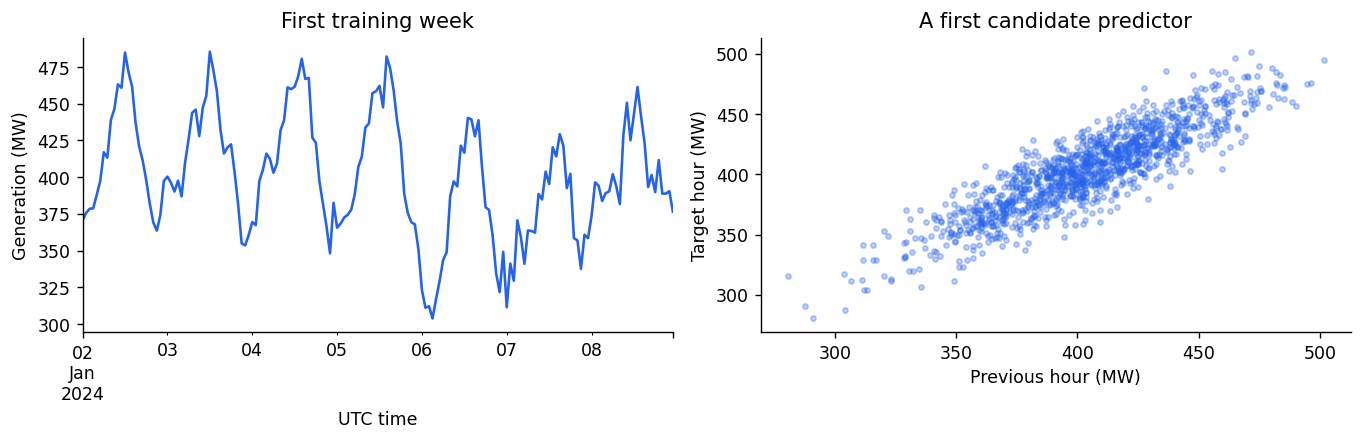

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
y_train.iloc[:7*24].plot(ax=axes[0], color="#2563eb")
axes[0].set(title="First training week", xlabel="UTC time", ylabel="Generation (MW)")
axes[1].scatter(X_train["lag1"], y_train, s=9, alpha=0.3, color="#2563eb")
axes[1].set(title="A first candidate predictor", xlabel="Previous hour (MW)",
            ylabel="Target hour (MW)")
fig.tight_layout()
plt.show()


## 4. Your first estimator: create → fit → predict

Start with **one complete input column** so missing weather readings do not distract
from learning the API.

`X_train[["lag1"]]` is a DataFrame with shape `(n, 1)`. The double brackets retain a
two-dimensional table. `X_train["lag1"]` is a Series with shape `(n,)`.
Sklearn expects a two-dimensional `X` even when there is only one feature.


In [6]:
from sklearn.linear_model import LinearRegression

X_train_one = X_train[["lag1"]]
X_valid_one = X_valid[["lag1"]]
print("Feature table:", X_train_one.shape)
print("Target:", y_train.shape)

demo_model = LinearRegression()
demo_model.fit(X_train_one, y_train)
print("Slope:", demo_model.coef_[0])
print("Intercept:", demo_model.intercept_)


Feature table: (1281, 1)
Target: (1281,)
Slope: 0.8837043767025519
Intercept: 47.00337481657948


Read the two central lines literally:

1. `LinearRegression()` creates an unfitted model object with its settings.
2. `fit(X_train_one, y_train)` estimates the intercept and slope and stores them in that object.

For this one-feature model, the fitted prediction is
\(\widehat y=\text{intercept_}+\text{coef_[0]}\times\text{lag1}\).
`LinearRegression` includes an intercept by default; you do not add a column of ones.

Learned attributes commonly end with an underscore: `coef_` and `intercept_`.
Constructor arguments, such as `fit_intercept=True`, are settings chosen before fitting.
`fit` returns the fitted model object itself; it does not return the prediction array.

Now call `predict` on new feature rows. It uses the learned parameters and does not
need the corresponding target values.


In [7]:
demo_prediction = demo_model.predict(X_valid_one)
print("Prediction type:", type(demo_prediction).__name__)
print("Prediction shape:", demo_prediction.shape)

display(pd.DataFrame({
    "previous_hour": X_valid["lag1"],
    "actual": y_valid,
    "prediction": demo_prediction,
}).head())


Prediction type: ndarray
Prediction shape: (427,)


,previous_hour,actual,prediction
timestamp,,,
2024-02-24 09:00:00+00:00,390.973193,403.331426,392.508097
2024-02-24 10:00:00+00:00,403.331426,442.702854,403.429121
2024-02-24 11:00:00+00:00,442.702854,421.882219,438.221824
2024-02-24 12:00:00+00:00,421.882219,410.706614,419.822538
2024-02-24 13:00:00+00:00,410.706614,406.343559,409.946607


`predict` returns a NumPy array in the same **row order** as the input. Attach the
original index when you want a pandas Series for time-series plotting.

For **one observation**, retain a two-dimensional row table with `iloc[[0]]`.
The two pairs of brackets here select one row, not one column.


In [8]:
one_row = X_valid_one.iloc[[0]]
print("One-row input shape:", one_row.shape)
print("One-row prediction:", demo_model.predict(one_row))

demo_prediction_series = pd.Series(demo_prediction, index=y_valid.index)
display(demo_prediction_series.head(3))


One-row input shape: (1, 1)
One-row prediction: [392.50809697]


timestamp
2024-02-24 09:00:00+00:00    392.508097
2024-02-24 10:00:00+00:00    403.429121
2024-02-24 11:00:00+00:00    438.221824
Freq: h, dtype: float64

**Checkpoint 1:** which call uses target values: `fit` or `predict`?
What shape does `X_valid_one.iloc[0]` have, and why is `iloc[[0]]` suitable for `predict`?
Answers are in section 17.


## 5. Evaluate predictions and establish baselines

Use the actual targets and predictions in the same row order.

| Function | What it measures | Better |
|---|---|---|
| `mean_absolute_error` | Average absolute error | Lower |
| `mean_squared_error` | Average squared error | Lower |
| `np.sqrt(mean_squared_error(...))` | RMSE, in the target's units | Lower |
| `r2_score` | Squared-error improvement relative to the evaluation target mean | Higher |

MAE and RMSE are in MW here. RMSE gives large misses more weight. Held-out R² can be
negative. For these regressors, `model.score(X, y)` returns **R²**, not RMSE.


In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("MAE (MW):", mean_absolute_error(y_valid, demo_prediction))
print("RMSE (MW):", np.sqrt(mean_squared_error(y_valid, demo_prediction)))
print("R2:", r2_score(y_valid, demo_prediction))
print("model.score gives R2:", demo_model.score(X_valid_one, y_valid))


MAE (MW): 12.941164331882836
RMSE (MW): 16.34241556468152
R2: 0.7849168460499801
model.score gives R2: 0.7849168460499801


A baseline checks whether the model achieves something useful. We use:

- **Training mean:** every prediction is the average training target.
- **Persistence:** predict the most recently observed generation.

`DummyRegressor(strategy="mean")` follows the same `fit`/`predict` API as other models.
It learns the target mean and ignores the feature values.


In [10]:
from sklearn.dummy import DummyRegressor

mean_model = DummyRegressor(strategy="mean")
mean_model.fit(X_train, y_train)
mean_prediction = mean_model.predict(X_valid)
persistence_prediction = X_valid["lag1"].to_numpy()

print("Training mean:", y_train.mean())
print("First three mean predictions:", mean_prediction[:3])
print("First three persistence predictions:", persistence_prediction[:3])


Training mean: 403.8407667024911
First three mean predictions: [403.8407667 403.8407667 403.8407667]
First three persistence predictions: [390.97319336 403.33142607 442.7028536 ]


To avoid retyping three formulas, define a short helper. **`regression_metrics` is our
own Python function, not a sklearn method.** It simply returns the three metrics we
just calculated. The dictionary keys become column names when we build a table.


In [11]:
def regression_metrics(actual, predicted):
    return {
        "MAE_MW": mean_absolute_error(actual, predicted),
        "RMSE_MW": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
    }

display(pd.DataFrame({
    "Training mean": regression_metrics(y_valid, mean_prediction),
    "Persistence": regression_metrics(y_valid, persistence_prediction),
    "One-feature OLS demo": regression_metrics(y_valid, demo_prediction),
}).T.round(3))


,MAE_MW,RMSE_MW,R2
Training mean,29.522,36.584,-0.078
Persistence,13.323,16.780,0.773
One-feature OLS demo,12.941,16.342,0.785


## 6. Learn preprocessing by hand

We now want to use all eight feature columns. Some weather measurements are missing.
We will fill them using **training medians**, then scale the inputs using **training
means and standard deviations**.

These are examples of **transformers**:

| Call | Meaning |
|---|---|
| `transformer.fit(X_train)` | Learn the transformation's parameters |
| `transformer.transform(X_valid)` | Apply an already learned transformation |
| `transformer.fit_transform(X_train)` | Learn from training inputs and transform them |

The targets are not filled. Missing targets in a real dataset usually cannot supply
supervised training labels; this toy dataset keeps them observed.

### 6a. Fill missing inputs


In [12]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train)
X_valid_imputed = imputer.transform(X_valid)

display(pd.Series(imputer.statistics_, index=X_train.columns,
                  name="Learned training medians"))
print("Missing entries after imputation:", np.isnan(X_train_imputed).sum())


lag1          4.042087e+02
lag24         4.040443e+02
roll24        4.050002e+02
temp_lag1     1.454757e+01
wind_lag1     5.909840e+00
hour_sin      1.224647e-16
hour_cos      6.123234e-17
is_weekday    1.000000e+00
Name: Learned training medians, dtype: float64

Missing entries after imputation: 0


`fit_transform` learns the training medians and fills training gaps. `transform` fills
validation gaps with **the same stored medians**. Calling `fit_transform(X_valid)` would
learn a new set of medians from the validation period.

These transformers normally return NumPy arrays, so we use new names such as
`X_train_imputed` and retain the original DataFrames and their column names.

### 6b. Scale the inputs

`StandardScaler` maps a feature to approximately \((x-\mu_{\mathrm{train}})/
s_{\mathrm{train}}\). This is especially useful for a penalty such as Ridge, whose
effect otherwise depends on the units of each feature.


In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_valid_scaled = scaler.transform(X_valid_imputed)

display(pd.DataFrame({
    "training_mean": scaler.mean_,
    "training_scale": scaler.scale_,
    "mean_after_scaling": X_train_scaled.mean(axis=0),
}, index=X_train.columns).round(3))


,training_mean,training_scale,mean_after_scaling
lag1,403.797,34.194,0.0
lag24,403.508,34.068,-0.0
roll24,403.787,16.395,-0.0
temp_lag1,14.595,5.302,-0.0
wind_lag1,5.861,1.461,-0.0
hour_sin,0.005,0.707,0.0
hour_cos,0.003,0.707,0.0
is_weekday,0.731,0.444,-0.0


Validation values are expressed in the training coordinate system. Their means do not
have to be zero. Fit a linear model on the transformed training array, then pass the
correspondingly transformed validation array to `predict`.


In [14]:
manual_model = LinearRegression()
manual_model.fit(X_train_scaled, y_train)
manual_prediction = manual_model.predict(X_valid_scaled)
display(pd.Series(regression_metrics(y_valid, manual_prediction)).round(3))


MAE_MW     11.197
RMSE_MW    14.045
R2          0.841
dtype: float64

## 7. Replace those manual steps with a Pipeline

This pipeline performs the same three operations in the same order:

1. Fill missing inputs.
2. Scale inputs.
3. Fit or apply the linear model.

The list contains pairs `("step_name", object)`. The names are labels we choose;
they let us inspect a step or tune its settings later.


In [15]:
from sklearn.pipeline import Pipeline

linear_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression()),
])

linear_pipeline.fit(X_train, y_train)
linear_prediction = linear_pipeline.predict(X_valid)
print("Largest difference from the manual result:",
      np.max(np.abs(linear_prediction - manual_prediction)))


Largest difference from the manual result: 0.0


The difference should be zero or very close to floating-point roundoff.

- `linear_pipeline.fit(X_train, y_train)` learns each preparation step from training
  data and fits the final model on the prepared inputs.
- `linear_pipeline.predict(X_valid)` applies the stored preparation and predicts.

**Pass the original feature DataFrame to the pipeline.** Passing `X_valid_scaled`
would ask it to impute and scale a second time.

`make_pipeline(SimpleImputer(...), StandardScaler(), LinearRegression())` is a shorter
alternative that assigns step names automatically. We use explicit names so the later
`model__alpha` syntax is easy to read.


## 8. Change the estimator: Ridge and a random forest

### 8a. Ridge

Ridge adds an L² penalty to linear regression. `alpha` controls the amount of shrinkage;
larger values penalize large coefficients more strongly. We choose `10.0` as a demonstration
setting, not as a universal recommendation.

The new model still uses exactly the same `fit` and `predict` calls.


In [16]:
from sklearn.linear_model import Ridge

ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=10.0)),
])
ridge_pipeline.fit(X_train, y_train)
ridge_prediction = ridge_pipeline.predict(X_valid)
display(pd.Series(regression_metrics(y_valid, ridge_prediction)).round(3))


MAE_MW     11.206
RMSE_MW    14.052
R2          0.841
dtype: float64

### Inspect settings and learned attributes

`get_params()` returns settings. `named_steps["model"]` gives the final estimator.
Because this model follows a scaler, its coefficients correspond to a change of one
training standard deviation in a feature, with the other transformed features fixed.
They are not automatically causal effects or reliable individual importance rankings.


In [17]:
print("Chosen alpha:", ridge_pipeline.get_params()["model__alpha"])
display(pd.Series(
    ridge_pipeline.named_steps["model"].coef_,
    index=X_train.columns,
    name="Ridge coefficients after scaling",
).round(3))


Chosen alpha: 10.0


lag1          19.439
lag24          3.808
roll24        -1.644
temp_lag1     -5.720
wind_lag1     -4.426
hour_sin      -0.566
hour_cos     -11.311
is_weekday     5.721
Name: Ridge coefficients after scaling, dtype: float64

### 8b. Random forest

A forest averages many regression trees. Their splits can represent thresholds and
interactions. More flexibility can reduce training error without improving future error.

- `n_estimators`: number of trees.
- `max_depth`: maximum depth of each tree.
- `min_samples_leaf`: minimum training observations in a leaf; larger values smooth the fit.
- `random_state`: makes the randomized procedure reproducible.

Keep imputation. Scaling is unnecessary for this tree comparison.


In [18]:
from sklearn.ensemble import RandomForestRegressor

forest_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=100, max_depth=8, min_samples_leaf=8,
        random_state=0, n_jobs=1,
    )),
])
forest_pipeline.fit(X_train, y_train)
forest_prediction = forest_pipeline.predict(X_valid)
display(pd.Series(regression_metrics(y_valid, forest_prediction)).round(3))


MAE_MW     11.391
RMSE_MW    14.379
R2          0.833
dtype: float64

## 9. Compare candidates on identical validation rows

The dictionary below stores fitted model objects under readable names. The second
dictionary stores their validation predictions. This is ordinary Python bookkeeping.
All listed fitted objects accept the same original eight-column `X`.

The one-feature OLS model in section 4 was an API demonstration. Here we compare OLS,
Ridge, and the forest using the **same full feature set**.


In [19]:
models = {
    "Training mean": mean_model,
    "Linear regression": linear_pipeline,
    "Ridge": ridge_pipeline,
    "Random forest": forest_pipeline,
}
validation_predictions = {"Persistence": persistence_prediction}
for name, model in models.items():
    validation_predictions[name] = model.predict(X_valid)

validation_scores = pd.DataFrame({
    name: regression_metrics(y_valid, prediction)
    for name, prediction in validation_predictions.items()
}).T.sort_values("RMSE_MW")
display(validation_scores.round(3))


,MAE_MW,RMSE_MW,R2
Linear regression,11.197,14.045,0.841
Ridge,11.206,14.052,0.841
Random forest,11.391,14.379,0.833
Persistence,13.323,16.780,0.773
Training mean,29.522,36.584,-0.078


A lower training error alone is insufficient. Compare the fitted models on training
and validation. All preprocessing remains fitted on training data when we calculate
both columns.


,Training_RMSE,Validation_RMSE
Training mean,34.142,36.584
Linear regression,13.667,14.045
Ridge,13.670,14.052
Random forest,11.278,14.379


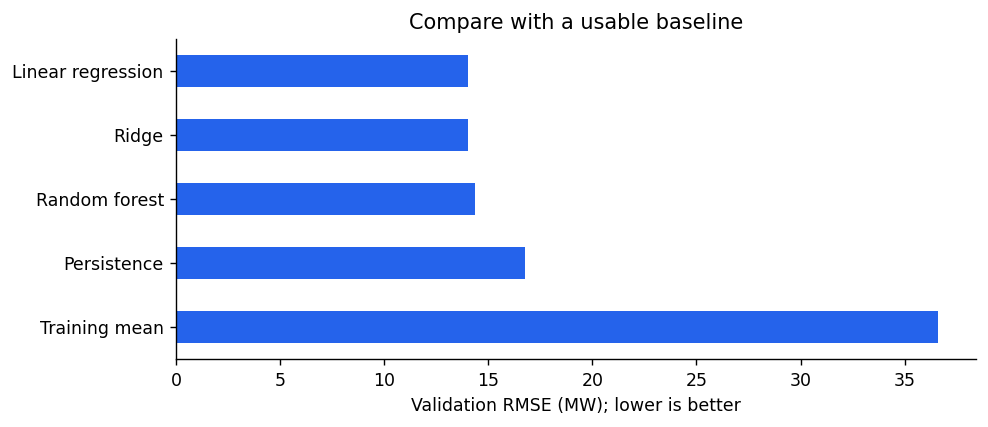

In [20]:
fit_comparison = pd.DataFrame({
    name: {
        "Training_RMSE": np.sqrt(mean_squared_error(y_train, model.predict(X_train))),
        "Validation_RMSE": validation_scores.loc[name, "RMSE_MW"],
    }
    for name, model in models.items()
})
display(fit_comparison.T.round(3))

fig, ax = plt.subplots(figsize=(8, 3.5))
validation_scores["RMSE_MW"].plot.barh(ax=ax, color="#2563eb")
ax.invert_yaxis()
ax.set(xlabel="Validation RMSE (MW); lower is better", ylabel="",
       title="Compare with a usable baseline")
fig.tight_layout()
plt.show()


**What to look for:** OLS and Ridge can be effectively tied. A forest can fit training
more closely yet be slightly worse on validation. Avoid presenting a tiny numerical
win as strong evidence of superiority. A baseline is allowed to win.

**Checkpoint 2:** which comparison tests the effect of Ridge's penalty while holding
the feature set fixed? Why would comparing the one-feature demo with full-feature Ridge
answer a different question?


## 10. Plot predictions and residuals; predict one new row

Use the Ridge model as a fixed example for diagnostics. The first panel compares a week
of predictions with observations. The second shows calibration; the third checks
whether residuals vary over time. A pattern motivates a further validation experiment.

Residuals here are **actual minus predicted**, so positive values mean underprediction.


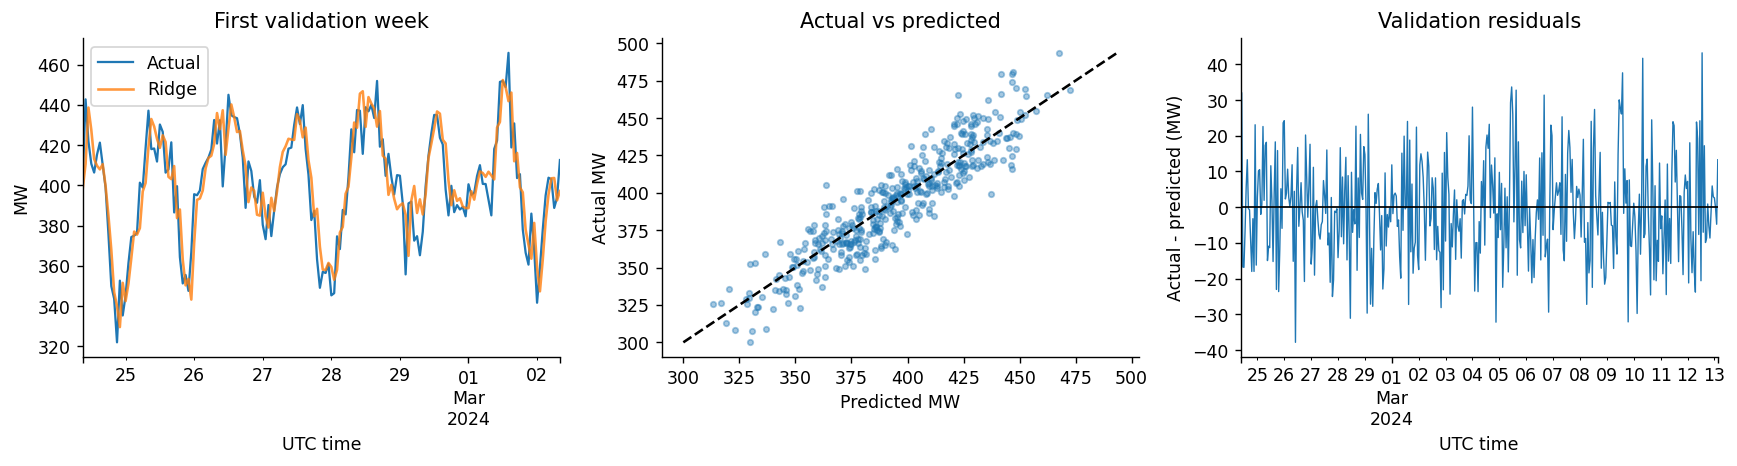

In [21]:
ridge_series = pd.Series(ridge_prediction, index=y_valid.index)
ridge_residual = y_valid - ridge_series

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
y_valid.iloc[:7*24].plot(ax=axes[0], label="Actual", linewidth=1.3)
ridge_series.iloc[:7*24].plot(ax=axes[0], label="Ridge", alpha=0.8)
axes[0].legend()
axes[0].set(title="First validation week", xlabel="UTC time", ylabel="MW")
axes[1].scatter(ridge_series, y_valid, s=10, alpha=0.4)
limits = [min(ridge_series.min(), y_valid.min()), max(ridge_series.max(), y_valid.max())]
axes[1].plot(limits, limits, color="black", linestyle="--")
axes[1].set(title="Actual vs predicted", xlabel="Predicted MW", ylabel="Actual MW")
ridge_residual.plot(ax=axes[2], linewidth=0.8)
axes[2].axhline(0, color="black", linewidth=1)
axes[2].set(title="Validation residuals", xlabel="UTC time", ylabel="Actual - predicted (MW)")
fig.tight_layout()
plt.show()


For a single forecast, supply one row with the same feature names and order. The pipeline
automatically performs its learned preparation. This example reuses one validation row
as an illustration; a future row would be built from history available at that time.


In [22]:
one_new_row = X_valid.iloc[[0]].copy()
print("One-row shape:", one_new_row.shape)
print("Ridge prediction:", ridge_pipeline.predict(one_new_row)[0], "MW")
display(one_new_row)


One-row shape: (1, 8)
Ridge prediction: 398.2257992900428 MW


,lag1,lag24,roll24,temp_lag1,wind_lag1,hour_sin,hour_cos,is_weekday
timestamp,,,,,,,,
2024-02-24 09:00:00+00:00,390.973193,403.783559,412.146636,16.66385,4.758674,0.707107,-0.707107,0.0


### Core milestone

You can now prepare a feature table, fit a model, obtain predictions, evaluate them,
handle missing inputs, use a pipeline, and try a second model family.

**For the shortest route, skip sections 11–12 and go to section 13.**
The optional sections below add candidates to the same validation comparison before
the final test. Do any validation experiments before section 13.


## 11. Optional: choose alpha with chronological cross-validation

`alpha` is a **hyperparameter**: a setting we choose, rather than a coefficient learned
by one call to `fit`. `GridSearchCV` tries a small list of settings.

First, `TimeSeriesSplit` creates expanding training sets followed by later evaluation
blocks **inside our original training period**. The indices it returns are row positions,
so use `iloc`. The splitter's evaluation indices are internal validation folds; they
are not our reserved final `X_test`.

These observations are equally spaced. For this one-hour forecast and availability
rule, we use the default zero gap. A different target horizon or reporting delay can
require a gap or custom splits.


In [23]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

cv = TimeSeriesSplit(n_splits=3)
fold_rows = []
for number, (fit_rows, check_rows) in enumerate(cv.split(X_train), start=1):
    fold_rows.append({
        "fold": number,
        "fit_rows": len(fit_rows),
        "check_rows": len(check_rows),
        "fit_through": X_train.index[fit_rows[-1]],
        "check_from": X_train.index[check_rows[0]],
        "check_through": X_train.index[check_rows[-1]],
    })
display(pd.DataFrame(fold_rows).set_index("fold"))


,fit_rows,check_rows,fit_through,check_from,check_through
fold,,,,,
1,321,320,2024-01-15 08:00:00+00:00,2024-01-15 09:00:00+00:00,2024-01-28 16:00:00+00:00
2,641,320,2024-01-28 16:00:00+00:00,2024-01-28 17:00:00+00:00,2024-02-11 00:00:00+00:00
3,961,320,2024-02-11 00:00:00+00:00,2024-02-11 01:00:00+00:00,2024-02-24 08:00:00+00:00


### Search the whole pipeline

`"model__alpha"` means the `alpha` setting of the step named `"model"`. The two underscores
separate the step name from its parameter.

Pass the **whole pipeline and the original training DataFrame** to the search. Then each
fold learns its own medians, scales, and model coefficients using only that fold's fitting
rows. Do not pass an array preprocessed using the entire training period.

Scikit-learn chooses the largest score. `"neg_root_mean_squared_error"` therefore uses
negative RMSE: a score of −10 is better than −20. Negate the reported score to recover RMSE.

`refit=True` fits the chosen setting again on all the data passed to `search.fit`.
Consequently, `search.predict(X_valid)` is ready to use afterward.


In [24]:
search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"model__alpha": [0.1, 10.0, 100.0]},
    cv=cv,
    scoring="neg_root_mean_squared_error",
    refit=True,
    n_jobs=1,
    error_score="raise",
)
search.fit(X_train, y_train)
print("Chosen settings:", search.best_params_)
print("Mean internal-fold RMSE:", -search.best_score_)


Chosen settings: {'model__alpha': 0.1}
Mean internal-fold RMSE: 14.090901499648291


`best_params_` holds the chosen settings. `best_estimator_` is the fitted pipeline.
`cv_results_` contains the settings and scores from the search.

The mean fold RMSE summarizes internal CV periods. It need not equal the RMSE on our
separate outer validation period. We add the tuned pipeline to that outer comparison;
we have still not used the final test.


In [25]:
cv_results = pd.DataFrame(search.cv_results_)
cv_results["mean_fold_RMSE"] = -cv_results["mean_test_score"]
display(cv_results[["param_model__alpha", "mean_fold_RMSE", "rank_test_score"]])

models["Tuned Ridge"] = search.best_estimator_
validation_predictions["Tuned Ridge"] = search.predict(X_valid)
display(pd.Series(regression_metrics(
    y_valid, validation_predictions["Tuned Ridge"]
)).round(3))


,param_model__alpha,mean_fold_RMSE,rank_test_score
0,0.1,14.090901,1
1,10.0,14.272277,2
2,100.0,14.931841,3


MAE_MW     11.197
RMSE_MW    14.045
R2          0.841
dtype: float64

## 12. Optional: a nonlinear feature in a linear model

A linear model can contain a square:
\(\widehat y=\beta_0+\beta_1\,T+\beta_2\,T^2+\cdots\).
It remains linear in its fitted coefficients.

`FunctionTransformer` wraps an ordinary function as a pipeline transformation.
The function below adds one fixed feature; it does not estimate anything from the target.
Because the map is inside the pipeline, prediction automatically adds the same feature.
Imputation and scaling still learn only from the training rows.

This is a single additional candidate with a prespecified penalty, not a large search
over every possible transformation.


In [26]:
from sklearn.preprocessing import FunctionTransformer

def add_temperature_square(frame):
    result = frame.copy()
    result["temperature_squared"] = result["temp_lag1"] ** 2
    return result

mapped_pipeline = Pipeline([
    ("features", FunctionTransformer(add_temperature_square, validate=False)),
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=10.0)),
])
mapped_pipeline.fit(X_train, y_train)
models["Ridge + temperature square"] = mapped_pipeline
validation_predictions["Ridge + temperature square"] = mapped_pipeline.predict(X_valid)
display(pd.Series(regression_metrics(
    y_valid, validation_predictions["Ridge + temperature square"]
)).round(3))


MAE_MW     10.914
RMSE_MW    13.646
R2          0.850
dtype: float64

## 13. Choose, freeze, refit, and make one final assessment

This cell works whether or not you ran sections 11–12. It compares the candidates that
are currently present in `validation_predictions`.

We use a simple, declared rule: select the lowest validation RMSE, including the
baselines. Small score differences are not proof that one family is superior. If you
prefer a simpler model in a near tie, decide that rule before inspecting the final test.


In [27]:
validation_scores = pd.DataFrame({
    name: regression_metrics(y_valid, prediction)
    for name, prediction in validation_predictions.items()
}).T.sort_values("RMSE_MW")
display(validation_scores.round(3))
selected_name = validation_scores.index[0]
frozen_choice = selected_name
print("Choice made using validation only:", frozen_choice)


,MAE_MW,RMSE_MW,R2
Ridge + temperature square,10.914,13.646,0.850
Linear regression,11.197,14.045,0.841
Tuned Ridge,11.197,14.045,0.841
Ridge,11.206,14.052,0.841
Random forest,11.391,14.379,0.833
Persistence,13.323,16.780,0.773
Training mean,29.522,36.584,-0.078


Choice made using validation only: Ridge + temperature square


Refit the selected model on training plus validation to use all observations available
before the final test period. `clone` copies a model's settings into a new **unfitted**
object; it does not copy the learned coefficients. This keeps the earlier fitted models
available for reference.

The persistence baseline needs no fitted model. The training-mean baseline is updated
using the same pre-test period as the selected model.

The test inputs include earlier observed test outcomes as historical lags. This is
valid for the successive one-hour-ahead protocol defined in section 1: those outcomes
have arrived by the time the later prediction is made. It would not implement a batch
forecast issued at the beginning of the entire test block.


In [28]:
from sklearn.base import clone

X_before_test = pd.concat([X_train, X_valid])
y_before_test = pd.concat([y_train, y_valid])

if selected_name == "Persistence":
    final_prediction = X_test["lag1"].to_numpy()
else:
    final_model = clone(models[selected_name])
    final_model.fit(X_before_test, y_before_test)
    final_prediction = final_model.predict(X_test)

test_predictions = {
    selected_name: final_prediction,
    "Persistence": X_test["lag1"].to_numpy(),
    "Training mean": np.repeat(y_before_test.mean(), len(y_test)),
}
test_scores = pd.DataFrame({
    name: regression_metrics(y_test, prediction)
    for name, prediction in test_predictions.items()
}).T
assert selected_name == frozen_choice
print("FINAL TEST:", len(y_test), "observations | Selected:", selected_name)
display(test_scores.round(3))


FINAL TEST: 428 observations | Selected: Ridge + temperature square


,MAE_MW,RMSE_MW,R2
Ridge + temperature square,11.096,13.802,0.796
Persistence,13.017,16.208,0.718
Training mean,25.073,30.555,-0.002


### How to explain the result

Use the numbers produced above to complete this account:

> I predicted one hour ahead from available history and calendar information. I compared
> a mean and persistence baseline with several fitted models. I chose **[model]** on a
> later validation period, refitted it using the pre-test data, and obtained test RMSE
> **[value] MW**, compared with persistence RMSE **[value] MW**. This is one future period
> on a toy dataset, so I would examine stability over additional periods in a real study.

The test is the final assessment of the frozen choice. Further model development needs
an evaluation design that does not repeatedly reuse this final result for selection.


## 14. Optional: numeric and categorical columns

This independent six-row example teaches an additional API. It does not change the
forecasting experiment above and is too small for a meaningful performance claim.

Suppose a table contains a numeric temperature and a text-valued region. A
`ColumnTransformer` sends different columns through different preparation steps.
`OneHotEncoder` represents a category using indicator columns; arbitrary region numbers
such as 1, 2, 3 would impose a numerical order.


In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

category_train = pd.DataFrame({
    "temperature": [10, 12, 14, 16, 18, 20],
    "region": ["north", "south", "north", "south", "north", "south"],
})
category_y = pd.Series([130, 145, 125, 136, 119, 130], name="demand")
category_new = pd.DataFrame({
    "temperature": [15, 15],
    "region": ["north", "coast"],
})
display(category_train)


,temperature,region
0,10,north
1,12,south
2,14,north
3,16,south
4,18,north
5,20,south


Each `ColumnTransformer` entry is a triple:
`("name", transformer, list_of_columns)`.
It concatenates the resulting numeric columns for the final model.

`handle_unknown="ignore"` allows a new category such as `"coast"` at prediction time.
Its category indicator block becomes all zeros; this does not teach the model a
data-supported effect for that new region. `sparse_output=False` makes the small
encoded matrix dense and easy to inspect.


In [30]:
numeric_preparation = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
category_preparation = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preparation = ColumnTransformer([
    ("numeric", numeric_preparation, ["temperature"]),
    ("category", category_preparation, ["region"]),
])
mixed_model = Pipeline([
    ("preparation", preparation),
    ("model", Ridge(alpha=1.0)),
])
mixed_model.fit(category_train, category_y)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preparation', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('category', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transfo

In [31]:
prepared_new = mixed_model.named_steps["preparation"].transform(category_new)
prepared_names = mixed_model.named_steps["preparation"].get_feature_names_out()
display(pd.DataFrame(prepared_new, columns=prepared_names))

category_result = category_new.copy()
category_result["prediction"] = mixed_model.predict(category_new)
display(category_result)


,numeric__temperature,category__region_north,category__region_south
0,0.0,1.0,0.0
1,0.0,0.0,0.0


,temperature,region,prediction
0,15,north,125.287437
1,15,coast,130.833333


## 15. Your compact sklearn reference

| Task | Call | What comes back or changes |
|---|---|---|
| Construct a model | `model = Ridge(alpha=10)` | An unfitted estimator object |
| Fit parameters | `model.fit(X_train, y_train)` | The object becomes fitted; returns itself |
| Predict | `model.predict(X_valid)` | An array of predictions |
| Fit and apply preparation | `imputer.fit_transform(X_train)` | Prepared training inputs |
| Apply stored preparation | `imputer.transform(X_valid)` | Prepared new inputs |
| Inspect linear coefficients | `model.coef_` | Learned coefficients after fitting |
| Inspect a pipeline step | `pipe.named_steps["model"]` | The contained estimator |
| Inspect settings | `pipe.get_params()` | Parameter dictionary |
| Change a setting | `pipe.set_params(model__alpha=100)` | Updated setting; fit again afterward |
| Fresh copy with same settings | `clone(pipe)` | Unfitted copy |
| Tune settings | `search.fit(X_train, y_train)` | CV search, then refit if requested |
| Access selected pipeline | `search.best_estimator_` | Fitted estimator chosen by CV |

### A reusable numeric-regression template

This is a reference snippet. Replace the feature tables and target Series with your
own prepared split; the imports and method calls are the same.

```python
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
import numpy as np

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=10.0)),
])
model.fit(X_train, y_train)
prediction = model.predict(X_valid)
rmse = np.sqrt(mean_squared_error(y_valid, prediction))
print(rmse)
```

**Most useful habit:** know what was learned from which rows. A pipeline manages
preprocessing consistently; you still define the split, the available inputs, and the
target correctly.


## 16. Common errors and the first thing to check

| Symptom | First check or fix |
|---|---|
| `ModuleNotFoundError` | Confirm `sys.executable` and the selected notebook kernel; install in that environment. |
| VS Code asks for `ipykernel` | Select the prepared `sklearn_tutorial` kernel. |
| `NameError` for a variable | Run the earlier cell that creates it, or restart and run from the top. |
| `NotFittedError` | Call `fit` on this model object before `predict`. |
| “Expected 2D array” | Use `df[["column"]]` for one feature or `df.iloc[[i]]` for one row. |
| “Input X contains NaN” | Include `SimpleImputer` in the numeric pipeline. |
| “Could not convert string to float” | Encode categorical columns, as in section 14. |
| Different feature names at prediction | Supply the same input columns in the same order used for fitting. |
| “Invalid parameter alpha for Pipeline” | Use the step-qualified key, here `model__alpha`. |
| Unexpectedly poor predictions after scaling | Pass raw inputs to a fitted pipeline; do not scale them a second time. |
| A score is negative | Identify the score: R² may be negative, while CV loss scorers deliberately use negative loss. |

If you edit feature construction or rerun cells out of order, old variables and fitted
objects can remain in memory. Restarting the kernel and running the intended path from
the top gives you a clean experiment.


## 17. Small exercises and answers

For model-changing exercises, work on training/validation before the final assessment
in section 13. The code below is reference text so running all cells does not silently
add extra model searches.

### Exercise 1 — Shapes and method arguments

Why is `X_valid_one.iloc[[0]]` suitable for prediction? Does `predict` require `y_valid`?

**Answer:** `iloc[[0]]` is a DataFrame of shape `(1, 1)` in the one-feature example.
`iloc[0]` is a one-dimensional Series. `fit(X, y)` learns from labeled rows; `predict(X)`
uses the learned model and receives only the features.

### Exercise 2 — Isolate the penalty

Which comparison isolates Ridge's penalty?

**Answer:** compare the full-feature OLS pipeline with the full-feature Ridge pipeline
on the same validation rows. Comparing one-feature OLS with eight-feature Ridge changes
both the feature set and the estimation method.

### Exercise 3 — Change one setting

Try a much larger Ridge penalty and evaluate it on validation. Predict what might
happen to coefficient magnitudes before running it.

```python
from sklearn.base import clone

strong_ridge = clone(ridge_pipeline)
strong_ridge.set_params(model__alpha=1000.0)
strong_ridge.fit(X_train, y_train)
strong_prediction = strong_ridge.predict(X_valid)
print(regression_metrics(y_valid, strong_prediction))
```

A larger penalty tends to shrink the coefficient vector more. Its validation error
can improve or worsen; shrinkage is a bias–variance tradeoff, not a guaranteed gain.

### Exercise 4 — Add one lag

How would you create a generation lag of two hours?

```python
# Add this alongside the other features in section 2, then rebuild the split:
X["lag2"] = raw["generation_mw"].shift(2)
```

When `X` already has the post-warm-up index, pandas aligns the assigned Series by timestamp.
The new feature is available under our one-hour-ahead rule. Refit each model using the
new feature table and compare on the same validation period.

### Exercise 5 — Which transformer call belongs on validation?

**Answer:** `transform`. The imputer and scaler learn their parameters from training.
Refitting either on validation changes the learned preparation and uses information
outside the fitting period. With a pipeline, `predict(X_valid)` performs the correct
stored transformations for you.


## Documentation and scope

The example data and explanations were written for this tutorial. The following
official references cover the APIs used here:

1. [Scikit-learn getting started](https://scikit-learn.org/stable/getting_started.html)
2. [LinearRegression: fit, predict, coefficients, and score](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
3. [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html)
4. [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)
5. [Pipelines and composite estimators](https://scikit-learn.org/stable/modules/compose.html)
6. [Common pitfalls: preprocessing and leakage](https://scikit-learn.org/stable/common_pitfalls.html)
7. [Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html)
8. [RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html)
9. [Metrics and scoring](https://scikit-learn.org/stable/modules/model_evaluation.html)
10. [TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html)
11. [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)
12. [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
13. [VS Code notebook kernels](https://code.visualstudio.com/docs/datascience/jupyter-kernel-management)

The suggested local environment uses Python 3.12. The code avoids the version-sensitive
`mean_squared_error(..., squared=False)` argument by taking the square root explicitly.
The optional categorical example uses `sparse_output=False`, available in sklearn 1.2
and later. The executed copy records the actual library versions in section 0.

This is preparation material using synthetic data, rather than an actual interview
assessment. Use it to practice the workflow and explain your choices in your own words.
